# บทที่ 3: คู่มือการสร้างกราฟฉบับสมบูรณ์ (The Complete Visualization Guide)

การสร้างกราฟไม่ใช่แค่ทำให้สวย แต่คือการ **"เล่าเรื่องจากข้อมูล"** (Data Storytelling) 📊🎨
ในบทนี้เราจะเรียนรู้การเลือกกราฟให้เหมาะกับโจทย์ และวิธีเขียน Code ด้วย `matplotlib` และ `seaborn`

## 🎯 สิ่งที่จะได้เรียนรู้
1. **Comparison**: Bar Chart, Line Chart
2. **Distribution**: Histogram, Boxplot
3. **Relationship**: Scatter Plot, Heatmap, Pairplot
4. **Practice**: ลองวิเคราะห์ข้อมูลจริง

---

## ⚡ Cheat Sheet: เลือกกราฟยังไงดี?

| ต้องการดูอะไร? | ใช้กราฟอะไร? | ฟังก์ชัน Seaborn |
| :--- | :--- | :--- |
| **เปรียบเทียบปริมาณ** (Categorical) | **Bar Chart** | `sns.barplot()` |
| **ดูแนวโน้ม/เวลา** (Time Series) | **Line Chart** | `sns.lineplot()` |
| **ดูการกระจายตัว** (Distribution) | **Histogram** | `sns.histplot()` |
| **ดู Outlier/การกระจาย** | **Boxplot** | `sns.boxplot()` |
| **ความสัมพันธ์ 2 ตัวแปร** (Correlation) | **Scatter Plot** | `sns.scatterplot()` |
| **ความสัมพันธ์หลายตัวแปร** | **Heatmap** | `sns.heatmap()` |
| **ภาพรวมทุกตัวแปร** | **Pairplot** | `sns.pairplot()` |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่ากราฟให้สวยงาม
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'Tahoma' # รองรับภาษาไทย
plt.rcParams['figure.figsize'] = (10, 6) # ขนาดกราฟมาตรฐาน

## 1. Bar Chart (กราฟแท่ง)
**Use Case:** เปรียบเทียบยอดขายของแต่ละสาขา, จำนวนพนักงานในแต่ละแผนก

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_22424\1367335390.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bar, x='Category', y='Values', palette='viridis')


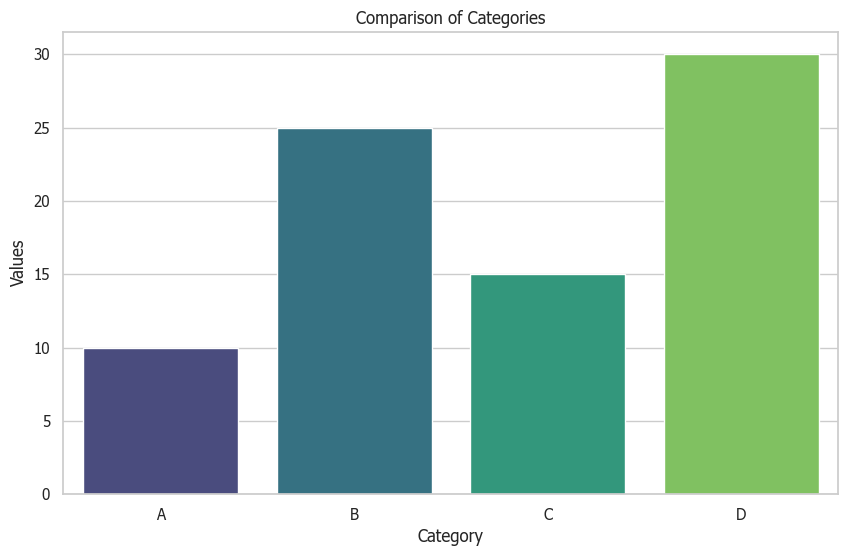

In [3]:
data = {'Category': ['A', 'B', 'C', 'D'], 'Values': [10, 25, 15, 30]}
df_bar = pd.DataFrame(data)

sns.barplot(data=df_bar, x='Category', y='Values', palette='viridis')
plt.title('Comparison of Categories')
plt.show()

## 2. Line Chart (กราฟเส้น)
**Use Case:** ยอดขายรายเดือน, ราคาหุ้น, อุณหภูมิที่เปลี่ยนแปลง

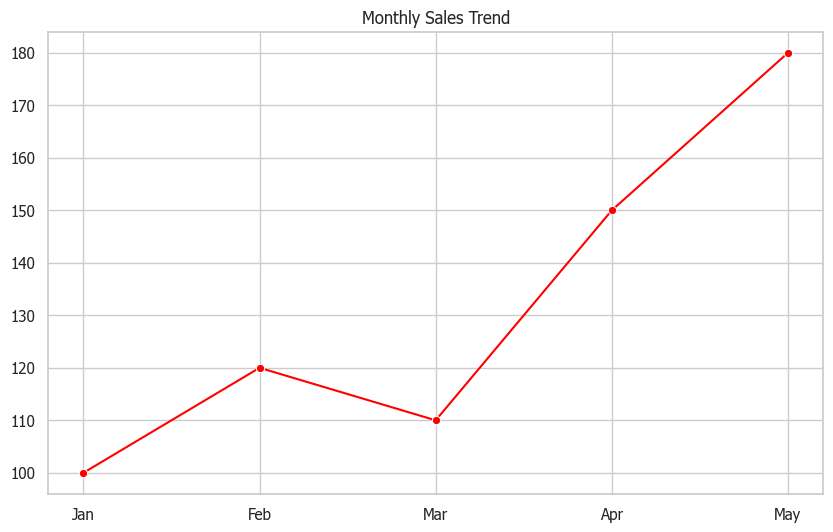

In [4]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May']
sales = [100, 120, 110, 150, 180]

sns.lineplot(x=months, y=sales, marker='o', color='red')
plt.title('Monthly Sales Trend')
plt.show()

## 3. Histogram & Boxplot (การกระจายตัว)
**Use Case:** ดูช่วงอายุลูกค้า, ดูการกระจายของรายได้, หา Outlier

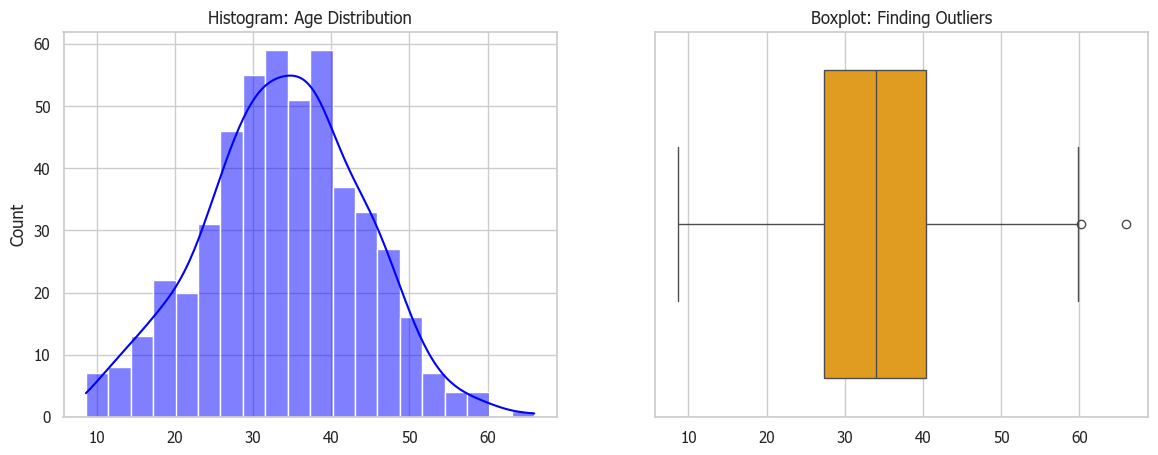

In [5]:
# สร้างข้อมูลจำลอง (อายุลูกค้า)
ages = np.random.normal(loc=35, scale=10, size=500)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(ages, bins=20, kde=True, ax=ax[0], color='blue')
ax[0].set_title('Histogram: Age Distribution')

# Boxplot
sns.boxplot(x=ages, ax=ax[1], color='orange')
ax[1].set_title('Boxplot: Finding Outliers')

plt.show()

## 4. Scatter Plot (แผนภาพการกระจาย)
**Use Case:** ดูความสัมพันธ์ เช่น ยิ่งโฆษณาเยอะ ยอดขายยิ่งเพิ่มไหม?

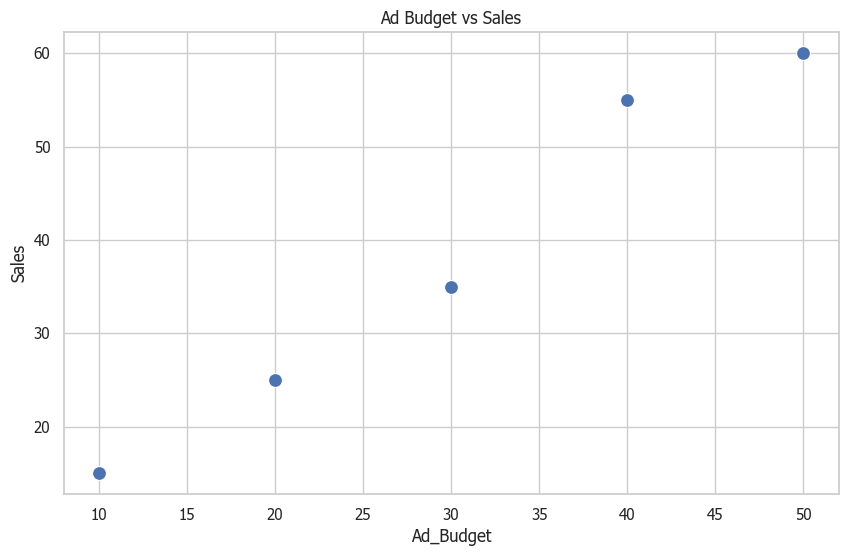

In [6]:
df_scatter = pd.DataFrame({
    'Ad_Budget': [10, 20, 30, 40, 50],
    'Sales': [15, 25, 35, 55, 60]
})

sns.scatterplot(data=df_scatter, x='Ad_Budget', y='Sales', s=100)
plt.title('Ad Budget vs Sales')
plt.show()

## 5. Heatmap (แผนภาพความร้อน)
**Use Case:** ดู Correlation Matrix (ความสัมพันธ์ของตัวแปรทั้งหมดในครั้งเดียว)
**ค่า Correlation:**
*   `1.0`: แปรผันตรงอย่างสมบูรณ์ (ตัวหนึ่งเพิ่ม อีกตัวเพิ่มตาม)
*   `-1.0`: แปรผกผันอย่างสมบูรณ์ (ตัวหนึ่งเพิ่ม อีกตัวลดลง)
*   `0.0`: ไม่มีความสัมพันธ์กัน

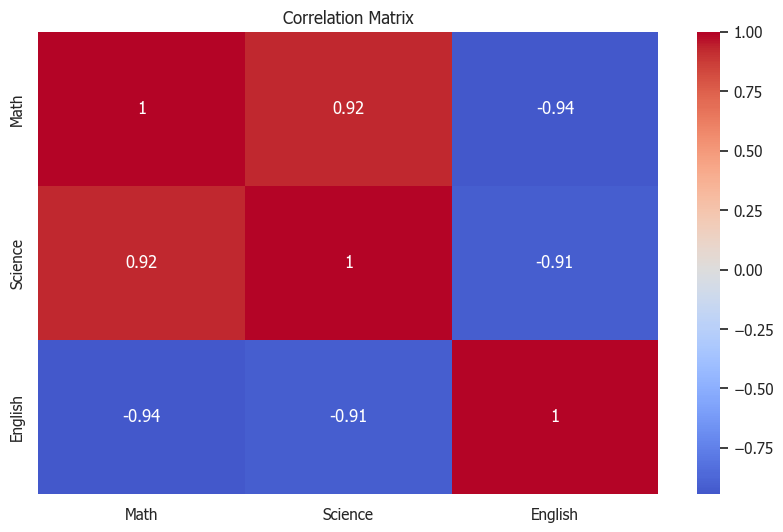

In [7]:
# ข้อมูลจำลอง
data = {
    'Math': [90, 80, 60, 95, 70],
    'Science': [85, 75, 65, 90, 60],
    'English': [50, 60, 90, 55, 85] # สังเกตว่าคนเก่งวิทย์/คณิต อาจจะไม่เก่งอังกฤษ
}
df_scores = pd.DataFrame(data)

# คำนวณ Correlation
corr = df_scores.corr()

# พล็อต Heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

## 6. Pairplot (พล็อตจับคู่)
**Use Case:** ดูภาพรวมของข้อมูลทุกคู่พร้อมกัน (เหมาะสำหรับเริ่มทำ EDA)

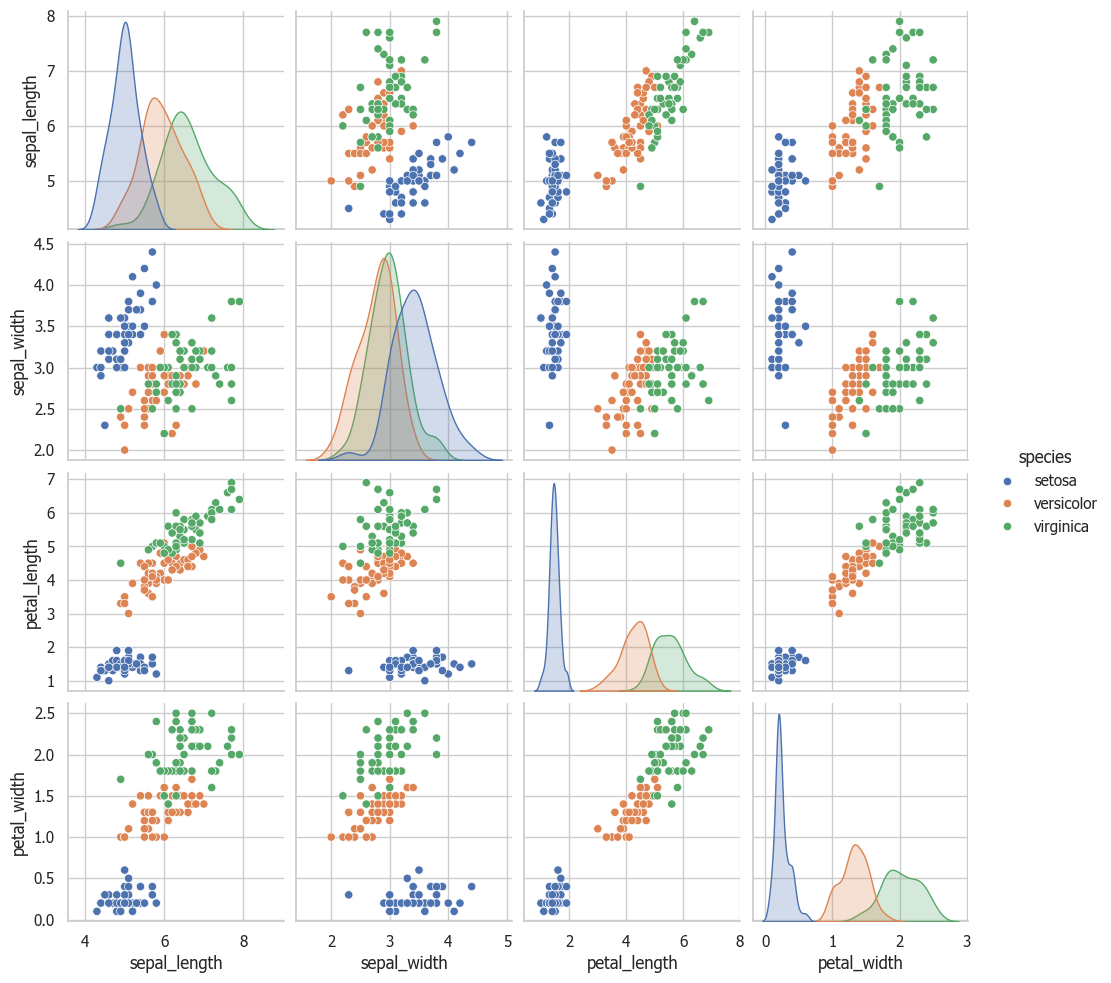

In [8]:
# ใช้ข้อมูลดอกไม้ Iris (มีใน Seaborn อยู่แล้ว)
df_iris = sns.load_dataset('iris')

# hue='species' คือแบ่งสีตามสายพันธุ์
sns.pairplot(df_iris, hue='species')
plt.show()

---

## 📝 แบบฝึกหัด (Practice)

ให้โหลดข้อมูล `consumerhealth.xls` จากโฟลเดอร์ `ข้อมูลและตัวอย่างงาน` แล้วลองสร้างกราฟต่อไปนี้:

1. **Histogram**: ดูการกระจายของยอดขาย (Sales)
2. **Line Chart**: ดูแนวโน้มยอดขายตามปี (Year)
3. **Bar Chart**: เปรียบเทียบแบรนด์ที่ขายดีที่สุด (Brands)

*(ลองเขียนโค้ดใน Cell ด้านล่างนี้เลยครับ)*

In [9]:
# เฉลยแบบฝึกหัด (Practice Solution)
# เราจะใช้ข้อมูล consumerhealth.xls ตามที่โจทย์กำหนดครับ

# 1. โหลดข้อมูล (Load Data)
try:
    # ไฟล์นี้ต้องข้าม 5 แถวแรกถึงจะเจอหัวตาราง (สังเกตจากไฟล์จริง)
    file_path = '../ข้อมูลและตัวอย่างงาน/consumerhealth.xls'
    df_health = pd.read_excel(file_path, header=5)

    # 2. ปรับแต่งโครงสร้างข้อมูล (Data Melting)
    # ข้อมูลเดิม: มีปี 2017, 2018, ... เป็นคอลัมน์ (Wide Format)
    # เราอยากได้: แถวเดียวบอก ปี และ ยอดขาย (Long Format)
    
    # ลบคอลัมน์ที่ไม่จำเป็น (ถ้ามี)
    df_health = df_health.dropna(how='all') # ลบแถวว่างทิ้ง
    
    # หาคอลัมน์ที่เป็นปี (ตัวเลข)
    year_cols = [col for col in df_health.columns if isinstance(col, int)]
    
    # Melt ให้เป็น Long Format
    df_melt = df_health.melt(
        id_vars=['Geography', 'Sub-Category', 'Brands'], # คอลัมน์ที่ "ตรึง" ไว้
        value_vars=year_cols,                           # คอลัมน์ที่ "ละลาย" ลงมา
        var_name='Year',                                # ชื่อคอลัมน์ใหม่สำหรับปี
        value_name='Sales'                              # ชื่อคอลัมน์ใหม่สำหรับยอดขาย
    )
    
    print("โหลดและปรับโครงสร้างข้อมูลสำเร็จ!")
    display(df_melt.head())

    # --- เริ่มสร้างกราฟ (Visualization) ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Histogram: ดูการกระจายของยอดขาย (Sales Distribution)
    # ใช้ log scale เพื่อแก้ปัญหาข้อมูลเบ้ (สินค้าขายดีกับขายไม่ดีต่างกันมาก)
    sns.histplot(df_melt['Sales'], bins=20, ax=axes[0], color='teal', kde=True)
    axes[0].set_title('Sales Distribution')
    axes[0].set_yscale('log') # ปรับแกน Y เป็น log เพื่อให้เห็นแท่งเตี้ยๆ ชัดขึ้น

    # 2. Line Chart: ดูแนวโน้มยอดขายรวมรายปี (Yearly Sales Trend)
    yearly_sales = df_melt.groupby('Year')['Sales'].sum()
    sns.lineplot(x=yearly_sales.index, y=yearly_sales.values, marker='o', ax=axes[1], color='orange', linewidth=2)
    axes[1].set_title('Total Sales Trend (2017-2023)')
    axes[1].set_xticks(yearly_sales.index) # บังคับโชว์ปีให้ครบ

    # 3. Bar Chart: สินค้าไหนขายดีสุด? (Top 5 Brands)
    top_brands = df_melt.groupby('Brands')['Sales'].sum().sort_values(ascending=False).head(5)
    sns.barplot(x=top_brands.values, y=top_brands.index, ax=axes[2], palette='viridis')
    axes[2].set_title('Top 5 Best Selling Brands')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"เกิดข้อผิดพลาด: {e}")

เกิดข้อผิดพลาด: "The following id_vars or value_vars are not present in the DataFrame: ['Sub-Category', 'Brands']"
